# Bessel cross products: order spectrum and radial modes

This notebook builds the standalone C++ example and plots its CSV output.
For $q=0.5$ and $k=20$, we compute orders $\nu$ satisfying

$$
J_\nu(kq)Y_\nu(k)-Y_\nu(kq)J_\nu(k)=0.
$$

The plotted eigenvalue is $\lambda=\nu^2$ for real orders and
$\lambda=-\eta^2$ for imaginary orders $\nu=i\eta$.

This is the radial **order spectrum at fixed wavenumber**, with Dirichlet
conditions at both radii. Install `../requirements.txt` before running.

In [1]:
from pathlib import Path
import csv
import subprocess
import numpy as np
import matplotlib.pyplot as plt

# Works from either the package root or its notebooks directory.
root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
assert (root / 'CMakeLists.txt').exists(), 'Start in standalone/ or standalone/notebooks/'
subprocess.run(['cmake', '-S', str(root), '-B', str(root/'build'),
                '-DCMAKE_BUILD_TYPE=Release'], check=True, capture_output=True)
subprocess.run(['cmake', '--build', str(root/'build'), '-j2'],
               check=True, capture_output=True)
k, q, imaginary_count = 20.0, 0.5, 6
prefix = root/'notebooks'/'spectrum'
exe = root/'build'/('spectrum.exe' if __import__('os').name == 'nt' else 'spectrum')
print(subprocess.check_output([str(exe), str(k), str(q), str(imaginary_count), str(prefix)], text=True))
with prefix.with_suffix('.csv').open() as f:
    modes = list(csv.DictReader(f))
radial = np.genfromtxt(str(prefix)+'_radial.csv', delimiter=',', names=True)
print(f"{sum(int(m['imaginary']) == 0 for m in modes)} real orders, {imaginary_count} imaginary orders")

Wrote 9 modes to spectrum.csv and spectrum_radial.csv

3 real orders, 6 imaginary orders


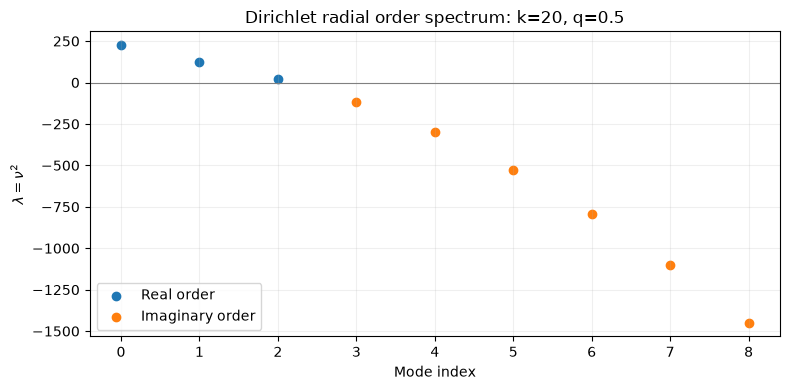

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
for imaginary, label, color in [(0, 'Real order', 'tab:blue'), (1, 'Imaginary order', 'tab:orange')]:
    group = [m for m in modes if int(m['imaginary']) == imaginary]
    ax.scatter([int(m['index']) for m in group], [float(m['eigenvalue']) for m in group], label=label, color=color)
ax.axhline(0, color='0.5', lw=0.8)
ax.set(xlabel='Mode index', ylabel=r'$\lambda = \nu^2$', title=f'Dirichlet radial order spectrum: k={k:g}, q={q:g}')
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(root/'notebooks'/'spectrum.png', dpi=160)
plt.show()

The radial eigenfunctions obey

$$
r^2R''+rR'+(k^2r^2-\lambda)R=0.
$$

Normalize them using $\int_q^1 R^2\,dr/r=1$. The sign of an eigenfunction
is arbitrary. The figures show all three real-order modes and the first
three imaginary-order modes; the CSV contains every requested mode.

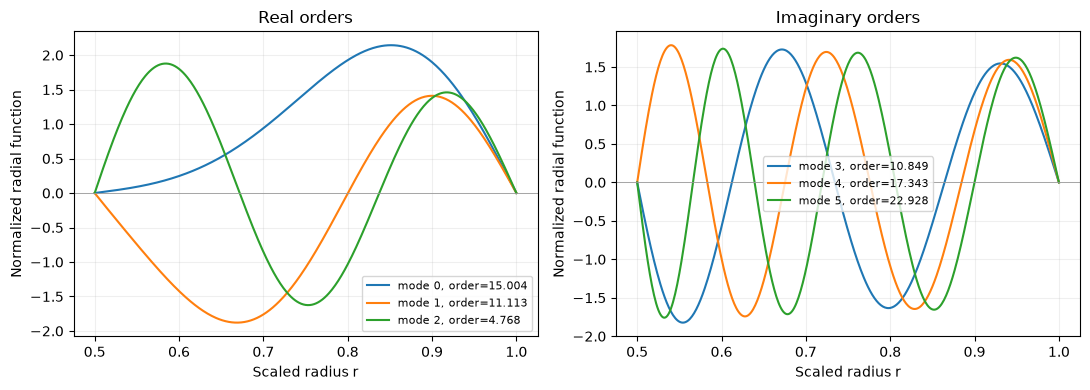

Maximum normalized boundary residual: 1.7e-10
Maximum weighted overlap error (401 samples): 2.86e-09


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
normalized = []
max_boundary = 0.0
for m in modes:
    i = int(m['index'])
    data = radial[radial['index'] == i]
    r, y = data['r'], data['value']
    weight = y*y/r
    norm = np.sqrt(np.sum(np.diff(r)*(weight[1:]+weight[:-1])/2))
    y = y/norm
    normalized.append(y)
    max_boundary = max(max_boundary, abs(y[0]), abs(y[-1]))
    imaginary = int(m['imaginary'])
    selected = [v for v in modes if int(v['imaginary']) == imaginary][:3]
    if m in selected:
        axes[imaginary].plot(r, y, label=f"mode {i}, order={float(m['order']):.3f}")
for ax, title in zip(axes, ['Real orders', 'Imaginary orders']):
    ax.set(xlabel='Scaled radius r', ylabel='Normalized radial function', title=title)
    ax.axhline(0, color='0.6', lw=.6)
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(root/'notebooks'/'radial_modes.png', dpi=160)
plt.show()
print(f'Maximum normalized boundary residual: {max_boundary:.3g}')
assert max_boundary < 1e-7
# Trapezoidal weighted overlap: discretization limits the accuracy.
r = radial[radial['index'] == 0]['r']
ys = np.array(normalized)
w = np.diff(r)/2
G = np.empty((len(modes), len(modes)))
for i in range(len(modes)):
    for j in range(len(modes)):
        integrand = ys[i]*ys[j]/r
        G[i,j] = np.sum(w*(integrand[1:]+integrand[:-1]))
error = np.max(np.abs(G-np.eye(len(modes))))
print(f'Maximum weighted overlap error (401 samples): {error:.3g}')
assert error < 1e-3

The numerical dispatch thresholds are empirical choices. The
example is validated at these parameters, but large-order asymptotics and
cancellation near roots need care. See `../docs/MANUAL.md` and
`../docs/VALIDATION.md` for the measured checks and limitations.

License: GPL-3.0-or-later.